# Workshop 3: Segmentación de clientes con Clustering
**K-Means vs. Agglomerative vs. DBSCAN** — Mall Customer Segmentation Data

Pregunta de negocio: *¿En cuántos grupos "naturales" se dividen los clientes del centro comercial y qué caracteriza a cada uno?*

## Fase 0 — Carga y preprocesamiento

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")

# Intentamos descargar el dataset automáticamente usando kagglehub
# para evitar el FileNotFoundError si el archivo local no existe.
"""""
try:
    import kagglehub
except ImportError:
    !pip install kagglehub -q
    import kagglehub
"""""

path = "data/"
df = pd.read_csv(f"{path}/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Shape:", df.shape)
print("\nNulos por columna:\n", df.isnull().sum())
print("\nTipos de dato:\n", df.dtypes)
print("\nDuplicados:", df.duplicated().sum())
df.describe().round(2)

Shape: (200, 5)

Nulos por columna:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Tipos de dato:
 CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Duplicados: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


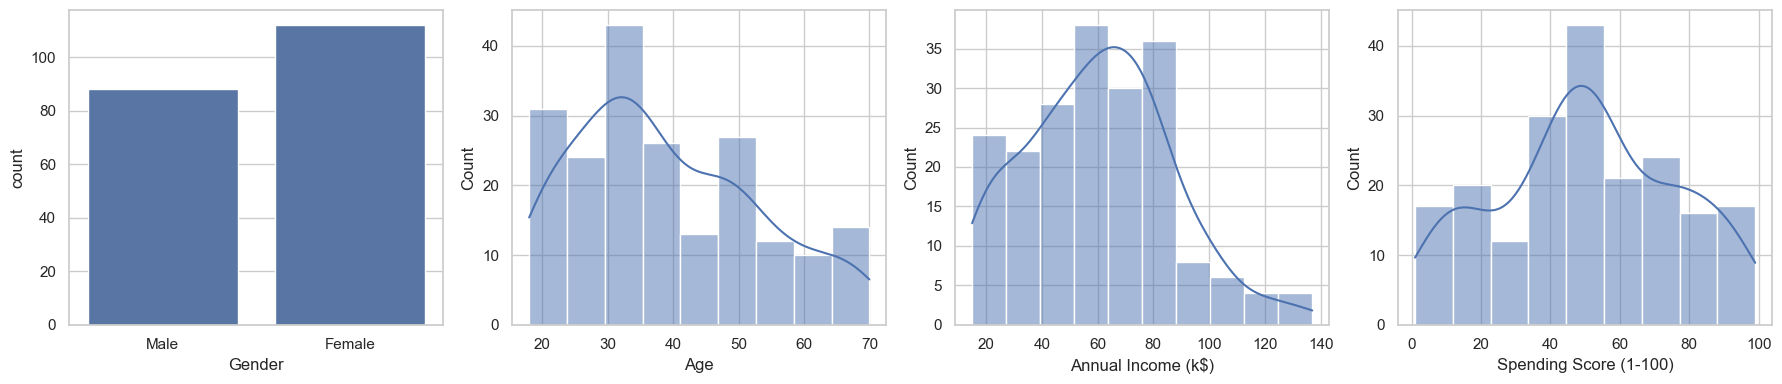

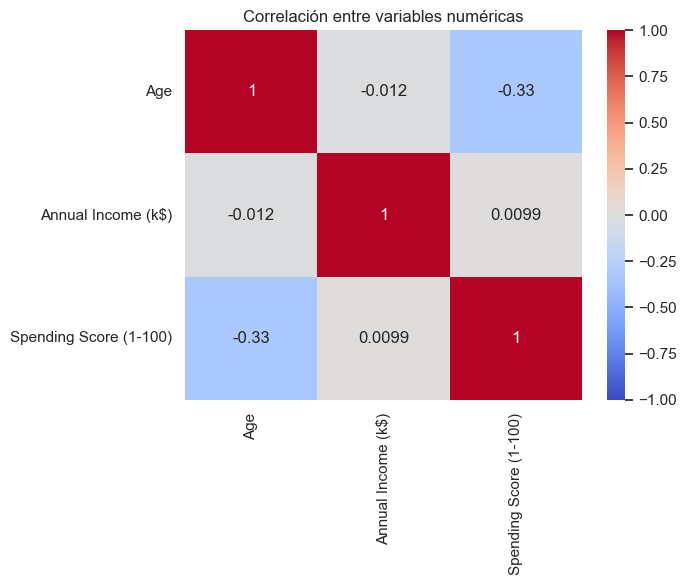

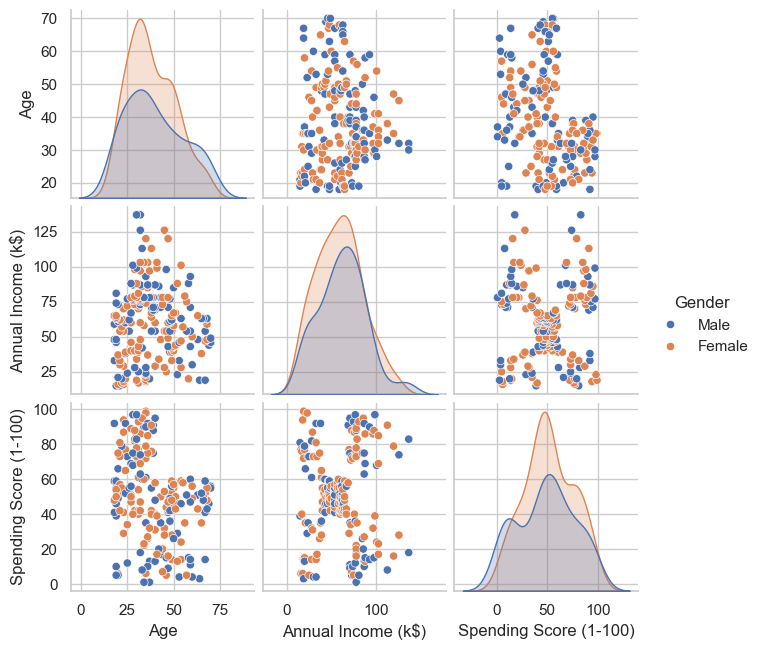

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.countplot(data=df, x="Gender", ax=axes[0])
for ax, col in zip(axes[1:], ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    sns.histplot(df[col], kde=True, ax=ax)
plt.tight_layout(); plt.show()

sns.heatmap(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas"); plt.show()

sns.pairplot(df.drop(columns="CustomerID"), hue="Gender", height=2.2); plt.show()

**Preguntas**

- **¿Hay valores nulos?** No. Las 200 filas tienen las 5 columnas completas, y tampoco hay filas duplicadas.
- **¿Tipos de dato?** `CustomerID`, `Age`, `Annual Income (k$)` y `Spending Score (1-100)` son numéricas (enteros). `Genre` es la única categórica (Male/Female, 112 mujeres y 88 hombres).
- Las correlaciones entre variables son bajas, así que ninguna variable es redundante y las 4 aportan información distinta. En el pairplot ya se alcanza a ver un bloque claro en *ingreso vs. spending score*.

### 2.2 y 2.3 — Selección de variables y codificación de `Genre`

`Genre` tiene solo 2 categorías y no tiene un orden natural. Con 2 categorías, mapear a 0/1 es equivalente a un One-Hot (queda una sola columna binaria, sin imponer un orden artificial entre más de dos categorías), así que uso `.map()`.

In [5]:
df = df.drop(columns="CustomerID", errors="ignore")
df["Gender_encoded"] = df["Gender"].map({"Male": 0, "Female": 1})
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_encoded
0,Male,19,15,39,0
1,Male,21,15,81,0
2,Female,20,16,6,1
3,Female,23,16,77,1
4,Female,31,17,40,1


### 2.4 — Estandarización

In [6]:
features = ["Gender_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print(df[features].std().round(2))
print("\nDesviación estándar tras escalar:", X_scaled.std(axis=0).round(2))

Gender_encoded             0.50
Age                       13.97
Annual Income (k$)        26.26
Spending Score (1-100)    25.82
dtype: float64

Desviación estándar tras escalar: [1. 1. 1. 1.]


**¿Por qué estandarizar?** Los tres algoritmos se basan en distancias (euclidiana). Sin escalar, la variable con mayor rango domina la distancia: `Annual Income` va de 15 a 137 (σ≈26) y `Age` de 18 a 70 (σ≈14), mientras que `Genre_encoded` solo vale 0/1. Entonces el género casi no pesaría y el ingreso mandaría sobre la edad solo por estar en otra unidad, no porque sea más importante. Con `StandardScaler` todas quedan con media 0 y desviación 1 y aportan de forma comparable. En DBSCAN además `eps` solo tiene sentido si todas las variables están en la misma escala.

## Fase 1 — K-Means

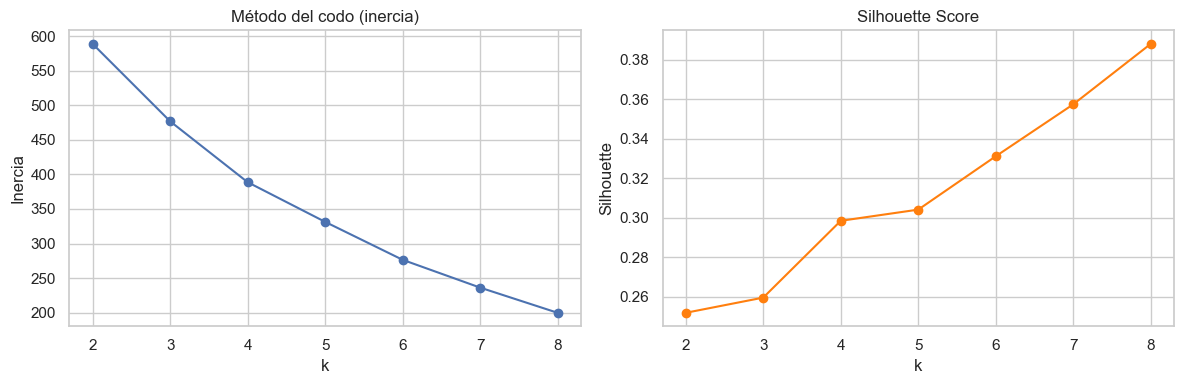

,k,Inercia,Silhouette Score,Caída de inercia
0,2,588.8,0.2518,NaN
1,3,476.8,0.2595,-112.0
2,4,388.7,0.2984,-88.1
3,5,331.3,0.3041,-57.4
4,6,276.4,0.3311,-54.9
5,7,236.2,0.3574,-40.2
6,8,199.8,0.3880,-36.4


In [7]:
ks = range(2, 9)
inertias, sil_km = [], []

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    sil_km.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Método del codo (inercia)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inercia")
axes[1].plot(list(ks), sil_km, "o-", color="tab:orange"); axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

tabla_km = pd.DataFrame({"k": list(ks), "Inercia": np.round(inertias, 1), "Silhouette Score": np.round(sil_km, 4)})
tabla_km["Caída de inercia"] = tabla_km["Inercia"].diff().round(1)
tabla_km

**Preguntas**

1. **¿El codo coincide con el k de mayor Silhouette?** No. El Silhouette sube casi de forma continua hasta k=8 (0.388), mientras que la inercia deja de caer tan fuerte alrededor de k=5–6 (la caída pasa de ~88 entre k=3→4 a ~57 entre k=4→5 y ~55 entre k=5→6; ya no hay un salto claro después). Con la variable binaria de género, a medida que sube k los clusters se parten por género y el Silhouette sube de forma "artificial", sin que aparezcan segmentos de negocio realmente nuevos.
2. **k elegido para K-Means: k = 5.** Es donde empieza a aplanarse la curva de inercia, el Silhouette ya es claramente mayor que con k≤3 (0.30 vs 0.26), los grupos resultan interpretables (ver Fase 7) y además coincide con lo que encuentra el método jerárquico (Fase 2).

## Fase 2 — Clustering jerárquico aglomerativo

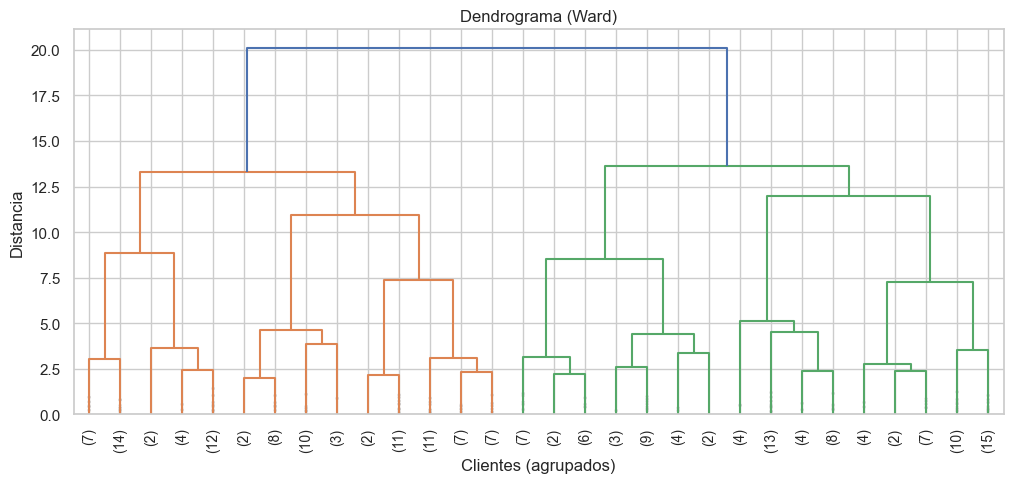

Distancia de las últimas 10 fusiones (de la última hacia atrás): [20.12 13.64 13.31 11.96 10.93  8.88  8.51  7.37  7.28  5.15]
Saltos entre fusiones consecutivas: [6.47 0.33 1.35 1.03 2.05 0.37 1.14 0.09 2.14]


In [8]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
plt.title("Dendrograma (Ward)"); plt.xlabel("Clientes (agrupados)"); plt.ylabel("Distancia")
plt.show()

# Distancias de las últimas fusiones: un salto grande indica que conviene cortar antes de esa fusión
dist = Z[-10:, 2][::-1]
print("Distancia de las últimas 10 fusiones (de la última hacia atrás):", dist.round(2))
print("Saltos entre fusiones consecutivas:", (dist[:-1] - dist[1:]).round(2))

In [9]:
sil_ag = []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    sil_ag.append(silhouette_score(X_scaled, lab))

tabla_ag = pd.DataFrame({"k": list(ks), "Silhouette Score": np.round(sil_ag, 4)})
tabla_ag

,k,Silhouette Score
0,2,0.2418
1,3,0.2483
2,4,0.2632
3,5,0.2870
4,6,0.3102
5,7,0.3456
6,8,0.3789


**Preguntas**

- **¿Cuántos grupos sugiere el dendrograma?** Mirando las distancias de fusión, el salto más grande (≈20.1 → 13.6) sugiere un corte en 2 grandes ramas, pero eso es demasiado grueso para segmentar clientes. Después de ese salto las distancias bajan de forma gradual (13.6, 13.3, 12.0, 10.9, 8.9...), y el siguiente salto apreciable está entre 10.9 y 8.9, lo que apunta a cortar en **5–6 grupos** (5 si se corta justo antes de esa caída, 6 después de ella).
- **¿Coincide con el mejor k según Silhouette?** No: el Silhouette del aglomerativo también crece hasta k=8 (0.379), por la misma razón que en K-Means. Sin embargo, para k=5 el aglomerativo (0.287) y K-Means (0.304) tienen valores parecidos y, como se ve en la tabla cruzada de abajo, producen casi los mismos grupos.

In [10]:
labels_km5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)
labels_ag5 = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X_scaled)
pd.crosstab(labels_km5, labels_ag5, rownames=["K-Means"], colnames=["Agglomerative"])

Agglomerative,0,1,2,3,4
K-Means,,,,,
0,0,39,0,0,0
1,3,0,26,0,0
2,5,0,2,36,0
3,52,0,0,2,0
4,1,0,5,0,29


## Fase 3 — DBSCAN

In [11]:
rows = []
for eps in [0.3, 0.5, 0.7, 0.9, 1.1]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_cl > 1 else np.nan
        rows.append((eps, ms, n_cl, n_noise, round(sil, 4) if not np.isnan(sil) else np.nan))

grid = pd.DataFrame(rows, columns=["eps", "min_samples", "n_clusters", "n_ruido", "silhouette (sin ruido)"])
grid

,eps,min_samples,n_clusters,n_ruido,silhouette (sin ruido)
0,0.3,3,14,144,0.6293
1,0.3,5,1,194,NaN
2,0.3,8,0,200,NaN
3,0.3,10,0,200,NaN
4,0.5,3,18,49,0.4746
5,0.5,5,9,105,0.5395
6,0.5,8,2,169,0.7089
7,0.5,10,2,178,0.7694
8,0.7,3,9,14,0.1322
9,0.7,5,7,37,0.2766


In [12]:
grid.pivot(index="eps", columns="min_samples", values="n_clusters").rename_axis("n_clusters"), \
grid.pivot(index="eps", columns="min_samples", values="n_ruido").rename_axis("n_ruido")

(min_samples  3   5   8   10
 n_clusters                 
 0.3          14   1   0   0
 0.5          18   9   2   2
 0.7           9   7   5   5
 0.9           3   2   4   5
 1.1           2   2   2   2,
 min_samples   3    5    8    10
 n_ruido                        
 0.3          144  194  200  200
 0.5           49  105  169  178
 0.7           14   37   76  106
 0.9            8   13   25   46
 1.1            0    7   10   10)

In [13]:
eps_sel, ms_sel = 0.9, 8
db = DBSCAN(eps=eps_sel, min_samples=ms_sel)
labels_db = db.fit_predict(X_scaled)

n_cl_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = int((labels_db == -1).sum())
mask = labels_db != -1
sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
print(f"eps={eps_sel}, min_samples={ms_sel} -> clusters: {n_cl_db}, ruido: {n_noise_db}, silhouette sin ruido: {sil_db:.4f}")
print(pd.Series(labels_db).value_counts().sort_index())

eps=0.9, min_samples=8 -> clusters: 4, ruido: 25, silhouette sin ruido: 0.2685
-1     25
 0    103
 1     10
 2     36
 3     26
Name: count, dtype: int64


**Preguntas**

1. **¿Cuántos clusters encontró DBSCAN?** Con `eps=0.9` y `min_samples=8`, 4 clusters. Es una región razonable: ni un solo cluster gigante ni casi todo marcado como ruido.
2. **¿Cuántos puntos de ruido?** 25 de 200 (12.5%).
3. **Efecto de los parámetros:**
   - Al **aumentar `eps`**, los vecindarios son más grandes, los clusters se fusionan y el ruido baja: con `min_samples=3` pasamos de 18 clusters (eps 0.5) a 9 (0.7), 3 (0.9) y 2 (1.1), con el ruido cayendo de 49 a 0.
   - Al **aumentar `min_samples`**, exigir más vecinos para ser punto núcleo hace que más puntos queden como ruido y que se pierdan o se fragmenten clusters pequeños: con `eps=0.7`, el ruido sube de 14 (3) a 37 (5), 76 (8) y 106 (10).
   - Con `eps` muy chico (0.3) casi todo es ruido; con `eps` grande (1.1) solo quedan 2 clusters grandes.
   - Nota: el Silhouette "sin ruido" de DBSCAN puede salir muy alto (ej. 0.77 con eps=0.5, ms=10) pero a costa de dejar casi 90% de los clientes como ruido, así que no es comparable ni útil.

## Fase 4 — Visualización PCA 3D

In [14]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(4))
print("Varianza explicada acumulada:", round(pca.explained_variance_ratio_.sum(), 4))

Varianza explicada por componente: [0.3369 0.2623 0.2326]
Varianza explicada acumulada: 0.8318


**¿Cuánta varianza capturan las 3 componentes?** ≈ 83% (PC1 33.7%, PC2 26.2%, PC3 23.3%). Es bastante para una visualización: se pierde ~17% de la información, así que la separación que se ve en 3D es confiable en general, pero puede que algunos puntos que parecen cercanos en el gráfico no lo sean tanto en las 4 dimensiones originales. Además la varianza está repartida de forma pareja entre las componentes (no hay una dominante), lo que es normal con solo 4 variables poco correlacionadas.

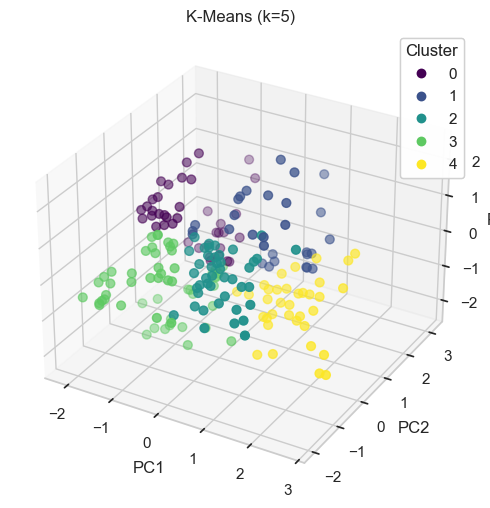

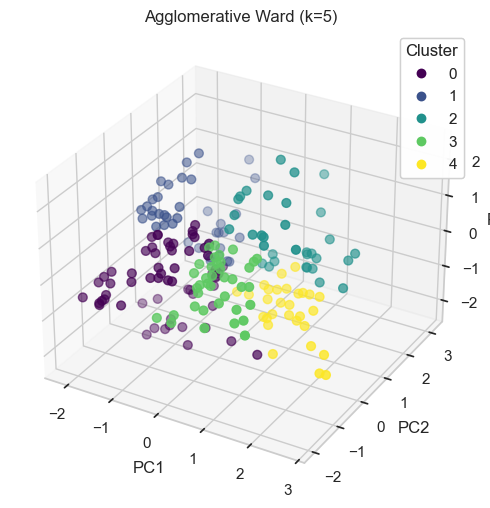

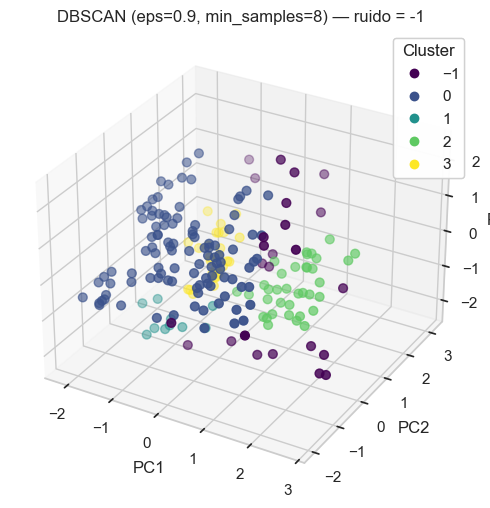

In [15]:
labels_kmeans = labels_km5
labels_agglomerative = labels_ag5

def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels, cmap="viridis", s=40)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title(title)
    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)
    plt.show()

plot_clusters_3d(X_pca, labels_kmeans, "K-Means (k=5)")
plot_clusters_3d(X_pca, labels_agglomerative, "Agglomerative Ward (k=5)")
plot_clusters_3d(X_pca, labels_db, f"DBSCAN (eps={eps_sel}, min_samples={ms_sel}) — ruido = -1")

**Observaciones:** K-Means y Agglomerative con k=5 dan particiones casi idénticas, con grupos compactos y bien repartidos en el espacio. En DBSCAN los puntos de ruido (`-1`) toman el color más oscuro de la paleta y se mezclan visualmente con los bordes de los clusters, lo que dificulta la lectura; además el resultado es desbalanceado: un solo cluster concentra 103 clientes (más de la mitad de la base) y los otros tres son pequeños (10, 36 y 26), con 25 puntos de ruido. Al ser un método basado en densidad no separa bien los grupos que están pegados entre sí.

## Fase 5 — Comparación final

In [16]:
sil_km5 = silhouette_score(X_scaled, labels_km5)
sil_ag5 = silhouette_score(X_scaled, labels_ag5)

comparacion = pd.DataFrame([
    ["K-Means", "k = 5", 5, "N/A", round(sil_km5, 4)],
    ["Agglomerative", 'k = 5, linkage="ward"', 5, "N/A", round(sil_ag5, 4)],
    ["DBSCAN", f"eps = {eps_sel}, min_samples = {ms_sel}", n_cl_db, n_noise_db, round(sil_db, 4)],
], columns=["Método", "Parámetros", "N° de clusters", "N° de puntos de ruido", "Silhouette Score"])
comparacion

,Método,Parámetros,N° de clusters,N° de puntos de ruido,Silhouette Score
0,K-Means,k = 5,5,N/A,0.3041
1,Agglomerative,"k = 5, linkage=""ward""",5,N/A,0.2870
2,DBSCAN,"eps = 0.9, min_samples = 8",4,25,0.2685


## Fase 6 — ¿Cuáles son las clases naturales?

**Respuesta: 5 grupos naturales, definidos con K-Means (k=5).**

- **Silhouette:** si solo miráramos el número, ganaría k=8 en K-Means (0.388) o incluso DBSCAN con eps bajo (hasta ~0.77), pero ninguno es una buena respuesta. En K-Means el Silhouette crece casi monótonamente con k porque el género binario permite partir cada grupo en dos, y en DBSCAN el score alto viene de ignorar el ruido (hasta 90% de los puntos).
- **Forma de los grupos:** los datos (sobre todo ingreso y spending score) forman bloques compactos y de tamaño parecido, que es justo donde K-Means funciona bien. DBSCAN, al tener que dejar 25 clientes (12.5%) como ruido, no asigna segmento a una parte importante de la base de clientes, lo que es un problema para marketing.
- **Consistencia:** K-Means y el jerárquico (Ward) coinciden casi por completo con k=5, lo que da confianza en que la estructura es real y no un artefacto del algoritmo.
- **Interpretabilidad:** con k=5 cada grupo tiene un perfil de negocio distinto y claro (siguiente fase). Con k=6–8 aparecen subgrupos que solo se distinguen por género.

A partir de aquí se usa K-Means con k=5.

## Fase 7 — Perfilado de los clusters

In [17]:
df["Cluster"] = labels_km5
num = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

print("Tamaño de cada cluster:"); print(df["Cluster"].value_counts().sort_index())
print("\nMEDIA"); display(df.groupby("Cluster")[num].mean().round(1))
print("MEDIANA"); display(df.groupby("Cluster")[num].median())
print("GÉNERO (proporción)"); display(df.groupby("Cluster")["Gender"].value_counts(normalize=True).unstack().round(2))

Tamaño de cada cluster:
Cluster
0    39
1    29
2    43
3    54
4    35
Name: count, dtype: int64

MEDIA


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,32.7,86.5,82.1
1,36.5,89.5,18.0
2,49.8,49.2,40.1
3,24.9,39.7,61.2
4,55.7,53.7,36.8


MEDIANA


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,32.0,79.0,83.0
1,37.0,86.0,17.0
2,49.0,50.0,43.0
3,23.5,39.5,58.0
4,57.0,54.0,43.0


GÉNERO (proporción)


Gender,Female,Male
Cluster,,
0,0.54,0.46
1,0.55,0.45
2,1.00,NaN
3,0.59,0.41
4,NaN,1.00


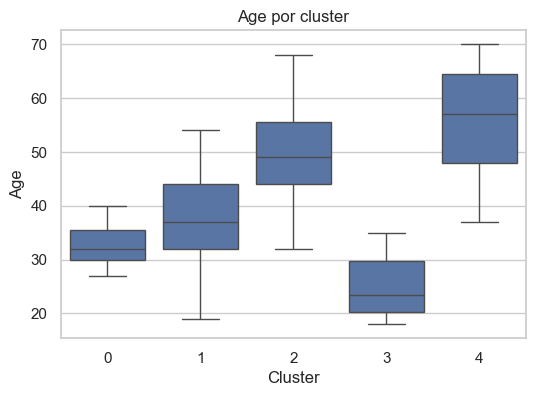

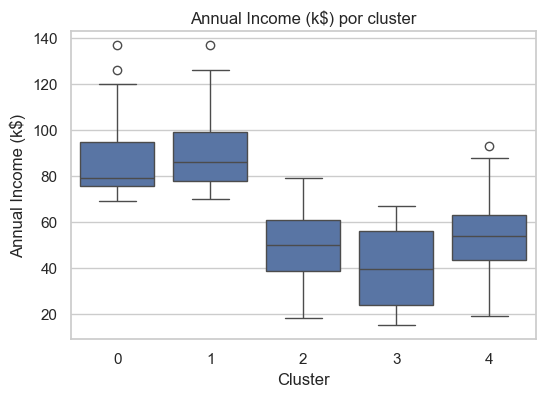

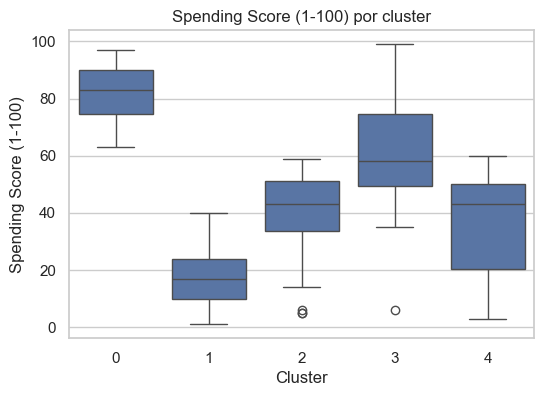

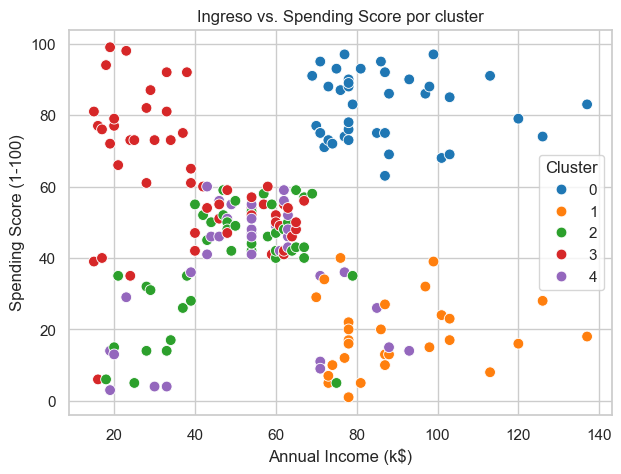

In [18]:
for col in num:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Cluster", y=col)
    plt.title(f"{col} por cluster"); plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Cluster", palette="tab10", s=60)
plt.title("Ingreso vs. Spending Score por cluster"); plt.show()

### Perfil de cada cluster (salido de los números)

| Cluster | n | Edad prom. | Ingreso prom. (k$) | Spending Score prom. | Género | Interpretación / "persona" |
|---:|---:|---:|---:|---:|---|---|
| 0 | 39 | 32.7 | 86.5 | 82.1 | mixto (≈50/50) | **Alto ingreso y alto gasto.** Clientes adultos jóvenes con gran poder adquisitivo que además lo usan: el segmento más rentable. |
| 1 | 29 | 36.5 | 89.5 | 18.0 | mixto | **Alto ingreso y bajo gasto.** Tienen dinero pero no lo gastan en el centro comercial: potencial sin aprovechar. |
| 2 | 43 | 49.8 | 49.2 | 40.1 | 100% mujeres | **Mujeres de mediana edad, ingreso y gasto medios.** Cliente promedio, comportamiento moderado. |
| 3 | 54 | 24.9 | 39.7 | 61.2 | mixto | **Jóvenes de ingreso bajo y gasto relativamente alto.** El grupo más grande; gastan por encima de lo que su ingreso sugiere. |
| 4 | 35 | 55.7 | 53.7 | 36.8 | 100% hombres | **Hombres mayores, ingreso medio y gasto medio-bajo.** Compradores más conservadores. |

> Nota: los números de cluster dependen de `random_state=42`; si cambian la semilla los índices pueden permutarse, pero los perfiles son los mismos.

**¿Qué cluster llama la atención?** El **cluster 1** (ingreso alto ≈ 90k$ pero Spending Score ≈ 18): es el que menos se esperaría, y es un segmento con mucho poder adquisitivo desaprovechado. Estrategia: campañas de fidelización y exclusividad (programas VIP, preventas, marcas premium, experiencias personalizadas, eventos) para entender qué no los está enganchando e incentivar que gasten más en el centro comercial. El cluster 3 (jóvenes con ingreso bajo y gasto alto) también sorprende y conviene cuidarlo con promociones, cuotas y cupones, ya que gastan más de lo que su ingreso sugiere.

## Fases 8–10 — El cluster como variable objetivo

Accuracy: 0.95
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      0.67      0.80         6
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00        11
           4       0.78      1.00      0.88         7

    accuracy                           0.95        40
   macro avg       0.96      0.93      0.93        40
weighted avg       0.96      0.95      0.95        40

[[ 8  0  0  0  0]
 [ 0  4  0  0  2]
 [ 0  0  8  0  0]
 [ 0  0  0 11  0]
 [ 0  0  0  0  7]]


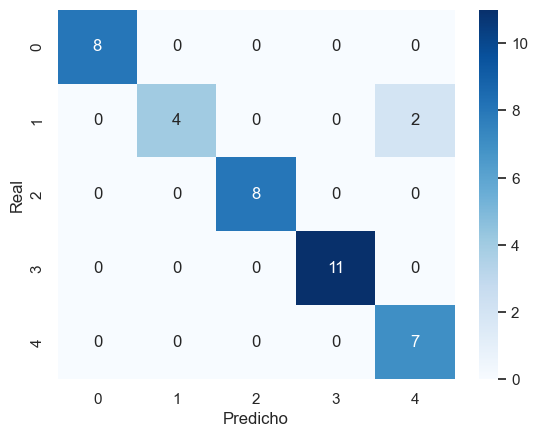

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

X = df[["Gender_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]]
y = df["Cluster"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5)),
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues"); plt.xlabel("Predicho"); plt.ylabel("Real"); plt.show()

**Sobre `stratify=y`:** mantiene la proporción de cada cluster en train y test. Con solo 200 clientes y clusters de 29 a 54 miembros, un split aleatorio podría dejar casi sin representación a algún cluster en el test.

**Clasificador elegido:** KNN (k=5) dentro de un `Pipeline` con `StandardScaler`, porque es un modelo basado en distancias (como el clustering).

**Preguntas de cierre**

1. **¿Qué tan bien predijo el cluster?** Muy bien: accuracy de 0.95 (38 de 40 clientes del test). Los clusters 0, 2 y 3 se predicen con precisión y recall de 1.00; el único punto débil es el cluster 1, con recall de 0.67 (4 de 6 bien clasificados).
2. **Accuracy alto, ¿qué dice de los clusters?** Que son muy separables en el espacio de características: un KNN simple puede reconstruir la asignación sin re-ejecutar el clustering, así que sirve para asignar segmento a un cliente nuevo. Ojo con la interpretación: las etiquetas salieron de esas mismas variables, así que un accuracy alto era esperable (no es una validación independiente de que los segmentos "existan" en la realidad), y con solo 40 clientes en el test cada error pesa 2.5 puntos.
3. **¿Dónde se equivocó?** Los únicos 2 errores fueron clientes del cluster 1 (alto ingreso, bajo gasto) predichos como cluster 4 (hombres mayores, ingreso y gasto medios). Los perfiles promedio son bastante distintos (ingreso ≈90 vs ≈54, spending ≈18 vs ≈37), por lo que lo más probable es que sean clientes en la frontera entre ambos grupos (hombres con gasto bajo y menos ingreso que el promedio de su cluster), ya que el género también influye en la distancia. No revisé esos dos casos uno a uno, así que es una hipótesis; con 6 clientes de ese cluster en el test, la métrica es poco estable.

## Reflexión final

**¿El método con mayor Silhouette fue el que usamos para definir los segmentos?** No. El mayor Silhouette lo dan configuraciones que no sirven para el negocio: valores de k altos (k=8), que parten los grupos por género, y DBSCAN con eps pequeño, cuyo score alto se logra ignorando al 50–90% de los clientes. Elegimos K-Means con k=5 porque entrega grupos compactos, interpretables, que asignan a todos los clientes y coinciden con el jerárquico. El Silhouette es una guía, no el criterio único.

**Recomendación de marketing por segmento (una frase cada uno):**

- **Cluster 0 (alto ingreso, alto gasto):** programa VIP/fidelización con acceso anticipado y beneficios exclusivos para retenerlos.
- **Cluster 1 (alto ingreso, bajo gasto):** campañas personalizadas y de marcas premium/experiencias para activar su gasto, empezando por investigar por qué no compran.
- **Cluster 2 (mujeres de mediana edad, gasto medio):** promociones y beneficios por volumen o recurrencia (combos, puntos) para subir el ticket promedio.
- **Cluster 3 (jóvenes, ingreso bajo, gasto alto):** cupones, cuotas y promociones en tendencias/moda, y comunicación por redes sociales.
- **Cluster 4 (hombres mayores, gasto medio-bajo):** ofertas ligadas a utilidad y calidad (tecnología, hogar, servicios) y atención más tradicional/presencial.